# 02: Shared-Sample Comparison

## Objective

Explore the behavior of the original NMC and MMC
estimators using the same generated text samples.

## Attribution

Both estimators are provided by REPLICA.
This notebook contributes experimental orchestration,
visualization and analysis.

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt

from replica.feature.frequency.sampled import (
    SampledUnigramSource,
    mc_estimate,
)

MODEL_NAME = "distilgpt2"
N_SAMPLES = 16
MAX_LEN = 20
SEED = 42

WORDS = ["the", "dog", "cat", "coriander"]

In [2]:
source = SampledUnigramSource(
    model_name=MODEL_NAME,
    n_samples=N_SAMPLES,
    max_len=MAX_LEN,
    device="cuda",
    seed=SEED,
    batch_size=4,
    gen_batch_size=4,
)

mmc = source.estimate_words([
    " " + word for word in WORDS
])

samples = source._samples

print("Generated samples:", len(samples))

/home/hydrogen/PROJECTS/replica/.venv-replica/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Generated samples: 16


In [3]:
pd.DataFrame({
    "sample_id": range(1, len(samples) + 1),
    "text": samples,
})

,sample_id,text
0,1,"for several years, and it began spreading and..."
1,2,All images published under the Creative Common...
2,3,III.III.\n\n\n\nPhysical evidence of a male su...
3,4,As Edward Snowden and James Comey continue to...
4,5,"Still, high-resolution dissecting video offers..."
5,6,Caroline all wore the best draft pick no matte...
6,7,Teres Wirbe 4X Wirbe 0X Watercolour Wirbe 4X Aqua
7,8,Email: mrottresselpore@jezebel.com; Twitter::
8,9,"DEFAULT USE > --password = -ok == -rm -r ""Debu..."
9,10,Extending the family to a village is easy. If ...


In [4]:
def to_surprisal(p):
    return -math.log2(p) if p > 0 else math.inf


rows = []

for word in WORDS:
    p_nmc = mc_estimate(word, samples)
    p_mmc = mmc[" " + word]

    rows.append({
        "word": word,
        "nmc_probability": p_nmc,
        "mmc_probability": p_mmc,
        "nmc_surprisal": to_surprisal(p_nmc),
        "mmc_surprisal": to_surprisal(p_mmc),
    })

results = pd.DataFrame(rows)

results

,word,nmc_probability,mmc_probability,nmc_surprisal,mmc_surprisal
0,the,0.028,2.978624e-02,5.158429,5.069210
1,dog,0.000,8.899829e-05,inf,13.455863
2,cat,0.000,6.746232e-05,inf,13.855558
3,coriander,0.000,1.337638e-07,inf,22.833809


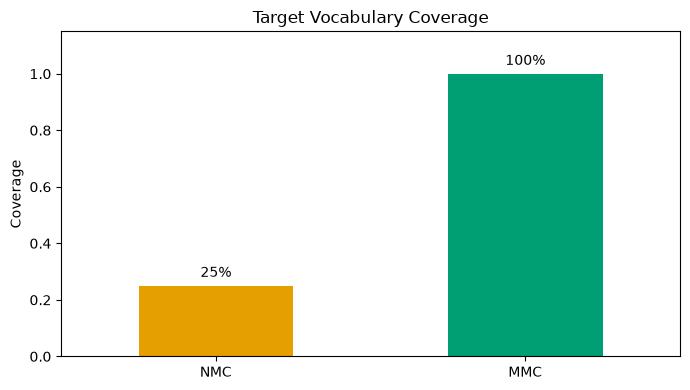

In [5]:
coverage = pd.Series({
    "NMC": (results["nmc_probability"] > 0).mean(),
    "MMC": (results["mmc_probability"] > 0).mean(),
})

ax = coverage.plot.bar(
    figsize=(7, 4),
    rot=0,
    color=["#E69F00", "#009E73"],
    width=0.5,
)

ax.set_title("Target Vocabulary Coverage")
ax.set_ylabel("Coverage")
ax.set_ylim(0, 1.15)

ax.bar_label(
    ax.containers[0],
    labels=[f"{value:.0%}" for value in coverage],
    padding=4,
)

plt.tight_layout()
plt.show()

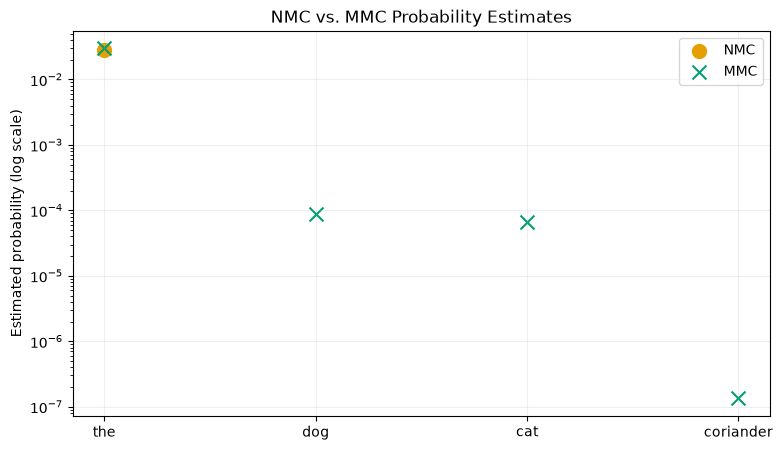

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

positive_nmc = results["nmc_probability"] > 0
positive_mmc = results["mmc_probability"] > 0

ax.scatter(
    results.loc[positive_nmc, "word"],
    results.loc[positive_nmc, "nmc_probability"],
    label="NMC",
    color="#E69F00",
    s=100,
    marker="o",
)

ax.scatter(
    results.loc[positive_mmc, "word"],
    results.loc[positive_mmc, "mmc_probability"],
    label="MMC",
    color="#009E73",
    s=100,
    marker="x",
)

ax.set_yscale("log")
ax.set_ylabel("Estimated probability (log scale)")
ax.set_title("NMC vs. MMC Probability Estimates")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

## Results and limitations

NMC provided non-zero estimates for one out of four
target words, whereas MMC provided non-zero estimates
for all four words.

The experiment illustrates the lexical coverage
problem associated with direct Monte Carlo counting.